testing the new adcCtrl algorithm in a notebook before I distill it into a .py file. this is just the work in progress.

In [128]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *
from scipy.optimize import minimize
from scipy.optimize import curve_fit
from scipy import ndimage
from psfGenerator_26B import *

first, we need an image to play with. let's start with a simulated image, then we'll move on to a real one once we get the ball rolling.

## New Broadband dispersed PSF generator

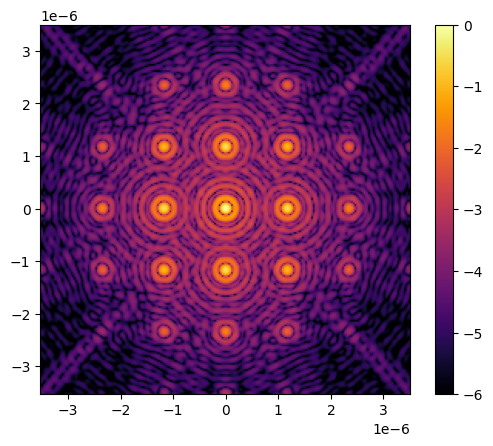

In [129]:
#overall parameters
telescope_diameter = 6.5 # meter
oversizing_factor = 1 #how much extra space next to the pupil (1 = no padding)
wavelength = 762E-9 #m, center wavelength
bandwidth = 120E-9 #m

grating_angle = 0
grating_fx = 10
grating_fy = 10

#define pupil grid
num_pupil_pixels = 128
pupil_grid_diameter = telescope_diameter * oversizing_factor
pupil_grid = make_pupil_grid(num_pupil_pixels, pupil_grid_diameter)

#create pupil
magellan_aperture_generator = make_magellan_aperture(False) #diameter is automatically 6.5
magellan_aperture = evaluate_supersampled(magellan_aperture_generator, pupil_grid, 4)
imshow_field(magellan_aperture)

#set up wavefront for propagation
wf = Wavefront(magellan_aperture, wavelength)
wf.total_power = 1

#propagator
spatial_resolution = wavelength / telescope_diameter
focal_grid = make_focal_grid(q=4, num_airy=30, spatial_resolution=spatial_resolution)

propagator = FraunhoferPropagator(pupil_grid, focal_grid)

###diffraction grating
#creating the cosine pattern
grating_grid = magellan_aperture.grid
rotated_grid = grating_grid.rotated(grating_angle)
cos_pattern_x = Field(np.cos(2*np.pi*(grating_fx/telescope_diameter) * rotated_grid.x),grating_grid)
cos_pattern_y = Field(np.cos(2*np.pi*(grating_fy/telescope_diameter) * rotated_grid.y),grating_grid)

#applying the cosine pattern to the phase apodizer
grating = PhaseApodizer(cos_pattern_x+cos_pattern_y)

#propagation
wf1 = grating.forward(wf)
wf2 = propagator.forward(wf1).power

imshow_field(np.log10(wf2 / wf2.max()), cmap='inferno', vmin=-6)
plt.colorbar()
plt.show()


In [130]:
magnitude_x = 0
magnitude_y = 0
mask = False

def disp(lam,lam0): #linear function of wavelength and the center wavelength
    dist = (lam - lam0) #distance from center wavelength
    return -dist

bb_psf = 0
                
for wlen in np.linspace(wavelength - bandwidth / 2., wavelength + bandwidth / 2., 15):
    k = 2 * np.pi / wlen #wavemumber
    opd_y = magnitude_y * disp(wlen,wavelength) * pupil_grid.y
    opd_x = magnitude_x * disp(wlen,wavelength) * pupil_grid.x
    opd = opd_y + opd_x 
    phase = opd * k #optical path difference between dispersed & not dispersed
    
    wf1 = Wavefront(magellan_aperture * np.exp(1j*phase),wavelength=wlen)
    wf1.total_power = 1/13 #normalizing each wavefront so that the total number of photons is 1 in the BB PSF
    wf2 = grating.forward(wf1)
    wf3 = propagator.forward(wf2)
    power = wf3.power
    
    if mask == True:
        mask_ap = make_circular_aperture(wavelength*10,[center_x * wavelength,center_y * wavelength])
        masking = mask_ap(power.grid)
        masking = np.abs(masking - 1)
        power *= masking
    
    bb_psf += power

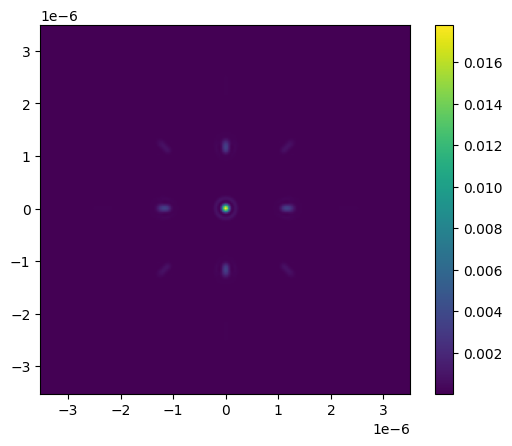

In [131]:
imshow_field(bb_psf)
plt.colorbar()

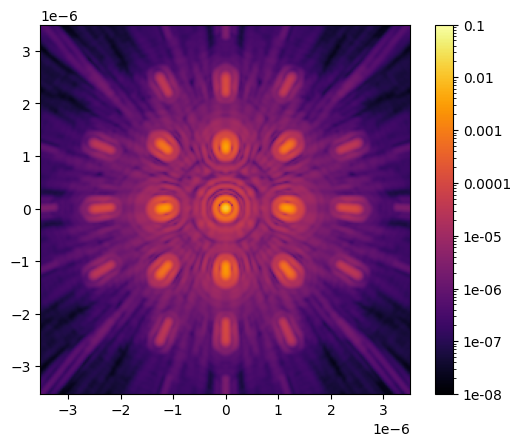

In [132]:
#testing the function written in the psfGenerator_26.py file
disp_y = 0.3

test = psf(wavelength,bandwidth,dispersion_y =disp_y)
imshow_psf(test)

### making sure the psf generator is in real units

In [133]:
#now calculate the size of the central PSF in mas
def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    mid = np.argmax(data)
    first_derivative = np.gradient(data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        data[right_valley:len(data)-1] = 0
        #print(right_valley)

    return data

def fwhm(data,mean_est=0):
    isolated = isolate_gaussian(data)
    x = np.arange(len(isolated))
    popt = curve_fit(gauss,x,isolated,p0=np.array([120,10]))

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return fwhm, mu, sigma

#define a function that takes in the psf and spits out the vertical FWHM, with the option to provide the plot for diagnostic purposes
def psf_vertical_fwhm(data,plotted=False):
    sliced = data.shaped[:,int(np.sqrt(data.size)/2)]
    sliced /= sliced.max()
    s = isolate_gaussian(sliced)
    width, mean, sd = fwhm(s,mean_est = len(sliced)/2 )

    if plotted:
        x = np.arange(len(s))
        extent = 15
        lowerbound = np.max(x) //2 - extent
        upperbound = np.max(x) //2 + extent
        #print(f'FWHM: {width}')

        plt.figure()
        plt.plot(x[lowerbound:upperbound],s[lowerbound:upperbound],'-o',label='Data')
        plt.plot(x[lowerbound:upperbound],gauss(x[lowerbound:upperbound],mean,sd),'r-',label='Fitted Gaussian')
        plt.vlines(mean - width/2,0,1,'gray',label=f'FWHM: {width:.3f}')
        plt.vlines(mean + width/2,0,1,'gray')
        plt.legend()
        plt.show()

    return width

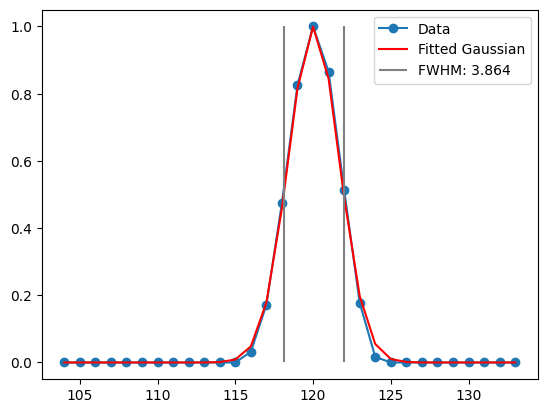

In [134]:
fwhm_test = psf_vertical_fwhm(test,plotted=True)

In [135]:
(wavelength / telescope_diameter) / 4

2.9307692307692306e-08

there are four pixels per resolution element, per the line that creates the focal grid (q=4). lam / D = 1.1723076923076922e-07, lam/D /4 = 2.93E-8, which means each pixel's angular size (in radians) is that ^^. this is also the grid.delta value. so we just need to convert that number into mas, and then we multiply the gaussian FWHM in pixels by that conversion factor to get PSF size in mas.

In [136]:
pix_size_mas = bb_psf.grid.delta * 206265 * 1000
print(pix_size_mas)

[6.04515115 6.04515115]


so we have about 6 mas/pixel. coincidentally this is almost the exact platescale of magao-x, except magao-x has a lot more pixels in the focal plane. so i suppose if i just changed the extent parameter in the focal grid generator, i would have a pretty decent analog of what's going on on the magao-x science cameras.

In [137]:
fwhm_test_mas = fwhm_test * pix_size_mas
print(fwhm_test_mas)

[23.35842512 23.35842512]


now let's see how it varies with the arbitrary dispersion magnitude parameter. then we can use this to tailor the disp function (in the psfGenerator) to make the dispersion_x and dispersion_y inputs be in real mas units.

In [138]:
pix_size_mas

array([6.04515115, 6.04515115])

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_83414/3911180894.py:3: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


Text(0, 0.5, 'psf size (mas)')

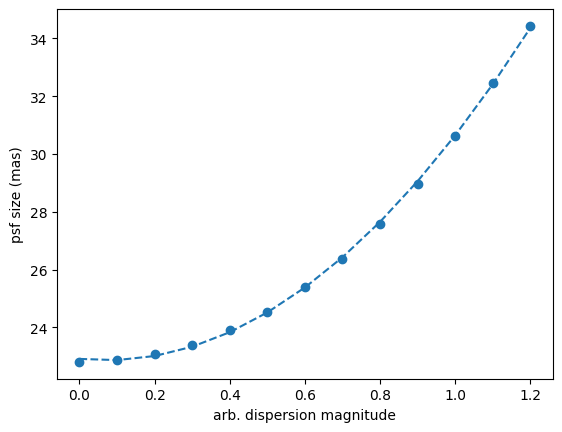

In [139]:
wavelength = 764E-9
bandwidth = 126E-9

disps = np.linspace(0,1.2,13)
fwhms = np.zeros(len(disps))

for i,disp_y in enumerate(disps):
    dispersed_psf = psf(wavelength,bandwidth,dispersion_y = disp_y)
    fwhms[i] = psf_vertical_fwhm(dispersed_psf.copy()) * pix_size_mas[0]

line = np.polyfit(disps,fwhms,2)
p = np.poly1d(line)
plt.scatter(disps,fwhms)
plt.plot(disps, p(disps),'--')
plt.xlabel('arb. dispersion magnitude')
plt.ylabel('psf size (mas)')

In [140]:
p

poly1d([ 9.04631186, -1.30817977, 22.90639388])

huh. well that's interesting. it's also what i happened to see in the real world: the fwhm varies quadratically with dispersion magnitude, even though the function I use to create the dispersion is linear. I wonder if i'm just measuring the FWHM wrong? is my range of dispersions just too high, like am I leaving the realm of physical possiblity? if i switch to my speckle pointing method do i see the same quadratic behaviors at these dispersion magnitudes?

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_83414/3911180894.py:3: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


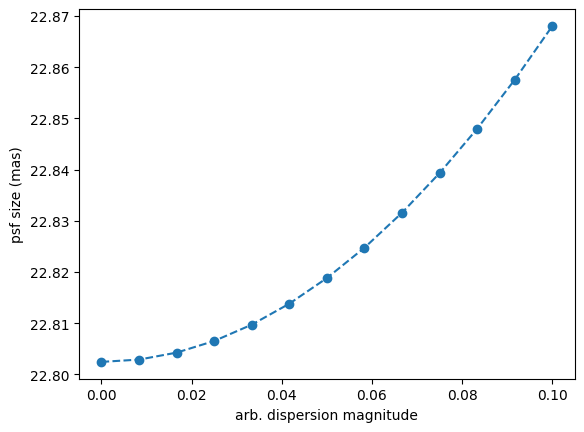

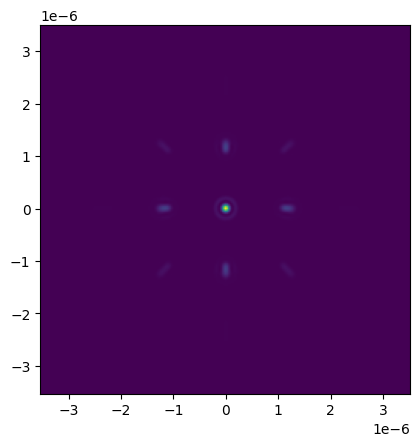

<Figure size 640x480 with 0 Axes>

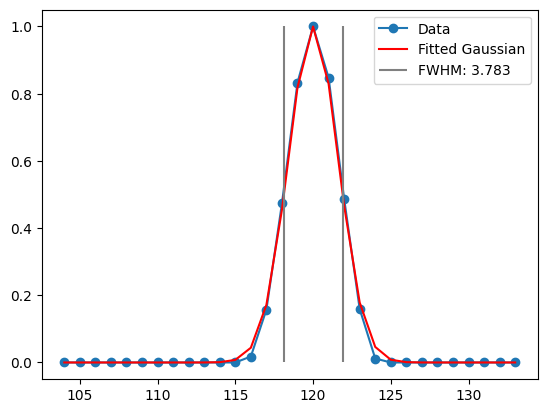

In [141]:
#is it just that i'm going too far?
wavelength = 764E-9
bandwidth = 126E-9

disps = np.linspace(0,0.1,13)
fwhms = np.zeros(len(disps))

for i,disp_y in enumerate(disps):
    dispersed_psf = psf(wavelength,bandwidth,dispersion_y = disp_y)
    fwhms[i] = psf_vertical_fwhm(dispersed_psf.copy()) * pix_size_mas[0]

line = np.polyfit(disps,fwhms,2)
p = np.poly1d(line)
plt.scatter(disps,fwhms)
plt.plot(disps, p(disps),'--')
plt.xlabel('arb. dispersion magnitude')
plt.ylabel('psf size (mas)')

plt.figure()
imshow_field(dispersed_psf)
plt.show()


plt.figure()
fwhm_test = psf_vertical_fwhm(dispersed_psf.copy(),plotted=True) * pix_size_mas[0]

well i don't think i'm going out of the linear range, and i also don't think that i'm measuring the FWHM incorrectly. we'll have to use the speckle pointing method to try and figure out what's going on here.

## New Speckle Pointing Method

In [142]:
from adc_algo import *

the new function i've generated to do the direction fitting requires the satellite spot to be cut out of the image already. so we need to do that first.

In [143]:
def window_field(data,center,width,height):
    '''crop a smaller field out of a big field. data must be an hcipy field.'''
    indx = data.grid.closest_to(center)
    y_ind, x_ind = np.unravel_index(indx, data.shaped.shape)
    cutout = data.shaped[(y_ind-height//2):(y_ind + height//2), (x_ind-width//2):(x_ind+width//2)]
    sub_grid = make_pupil_grid([width, height], [width * data.grid.delta[0], height * data.grid.delta[1]])
    return Field(cutout.ravel(), sub_grid)

def crop_image(image,extent=100,mask_diam=0.5E-6): 
    '''cuts out a centered PSF with the central core masked'''
    img_normalized = image/np.max(image)

    img_subtracted = img_normalized >0.1
    center_of_intensity = np.array([sum(img_subtracted*img_subtracted.grid.x)/sum(img_subtracted),sum(img_subtracted*img_subtracted.grid.y)/sum(img_subtracted)])
    mask_ap = make_circular_aperture(mask_diam,center_of_intensity)
    mask = mask_ap(img_subtracted.grid)
    mask = abs(mask - 1)
    image = mask * image

    image = window_field(image,[center_of_intensity[0],center_of_intensity[1]],extent,extent)
    image = Field([x if x>0 else 0 for x in image],image.grid)

    return image

def speckle_cutout(img,speckle_number,angle=0,freq=10,window_size=30):
    extent=1E-6
    separation = f * wavelength / telescope_diameter 
    speckle_coords = np.array([
        [0,           separation],
        [separation,  0],
        [0,          -separation],
        [-separation, 0]
    ])
    speckle_center = speckle_coords[speckle_number]
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-angle))(img.grid)
    speckle_img = rect * img.copy()

    max_pixel = speckle_img.grid[np.argmax(speckle_img)]
    new_img = window_field(img,[max_pixel[0],max_pixel[1]],window_size,window_size)
    return np.array(new_img.shaped)

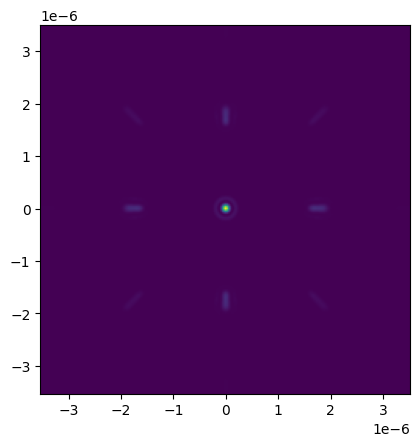

In [144]:
wavelength = 764E-9
bandwidth = 126E-9
disp_y = 0
f = 15
angle=0

img = psf(wavelength, bandwidth, dispersion_y=disp_y, angle=angle, freq=f)
imshow_field(img)
plt.show()

In [145]:
#first, crop the image so it only contains the relevant parts. this simulates the step where you have the whole science camera image.
cropped = crop_image(img,200,mask_diam=0.5E-6)
#then, use the known sparkle parameters to extract a single satellite spot.
speckle_img = speckle_cutout(cropped.copy(),0,angle=0,freq=f)

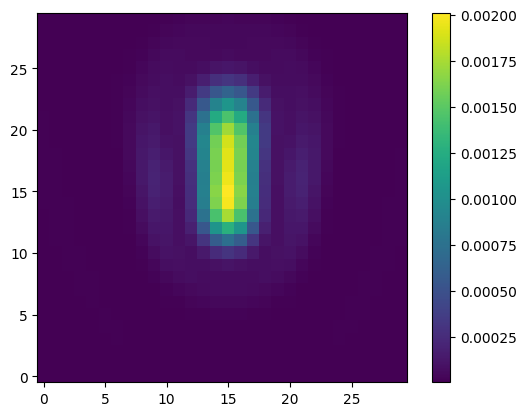

In [146]:
plt.imshow(speckle_img,origin='lower')
plt.colorbar()

### New version of algorithm
the algorithm takes just the cutout image as an input, so now we can see how it measures up.

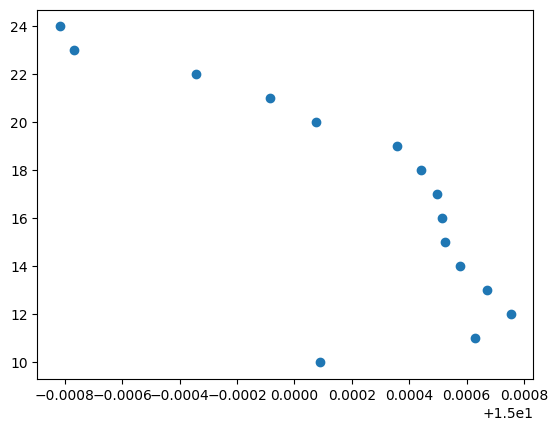

In [147]:
xcoords, ycoords = speckle_angle(speckle_img,'vertical',threshold_ratio=0.3,core_ratio=0.1)
plt.scatter(xcoords,ycoords)

In [148]:
#and now calculate the direction (slope) of that line:
pointing_x,pointing_y = spot_direction(xcoords,ycoords)
angle = np.atan(pointing_y / pointing_x)
print(pointing_x,pointing_y)
print(np.degrees(angle))

-8.971077362458142e-05 0.9999999959759887
-89.99485995128757


now let's see if it can do the pointing offset thing with enough precision.

In [149]:
wavelength = 764E-9
bandwidth = 126E-9
disp_y = 0
f = 15
angle=0

img = psf(wavelength, bandwidth, dispersion_y=disp_y, angle=angle, freq=f)
cropped = crop_image(img,200,mask_diam=0.5E-6)

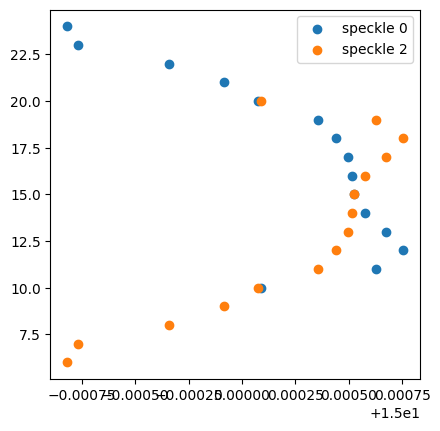

In [150]:
speckle0 = speckle_cutout(cropped,0,angle=angle)
speckle2 = speckle_cutout(cropped,2,angle=angle)

xcoords0, ycoords0 = speckle_angle(speckle0,'vertical',threshold_ratio=0.3,core_ratio=0.1)
xcoords2, ycoords2 = speckle_angle(speckle2,'vertical',threshold_ratio=0.3,core_ratio=0.1)

fig, ax = plt.subplots(1)
ax.scatter(xcoords0,ycoords0,label='speckle 0')
ax.scatter(xcoords2,ycoords2,label='speckle 2')
ax.legend()
ax.set_box_aspect(1)

In [151]:
pointing_x0,pointing_y0 = spot_direction(xcoords0,ycoords0)
angle0 = np.atan2(pointing_y0,pointing_x0)
print(f'speckle zero: {np.degrees(angle0):.4f}')

pointing_x2,pointing_y2 = spot_direction(xcoords2,ycoords2)
angle2 = np.atan2(pointing_y2,pointing_x2)
print(f'speckle two: {np.degrees(angle2):.4f}')

speckle zero: 90.0051
speckle two: -90.0051


that seems to work pretty well, but the angles aren't exactly what i'd expect them to be, e.g. a 28° grating angle does not translate to a 62° measurement. at 0° on the other hand, it does get the angle right. but as long as theyre pointing in the same direction, the bias will subtract out. so maybe it's fine?

let's think about this in the context of a satellite spot oriented at 45°. in that sense, i should be plotting the centers of intensity versus the length of the diagonal value of the pixel size. as in, the dependent variable is no longer one pixel, it is now dependent on the angle that's being input.

what if, to solve this, instead of rotating the speckle aperture to match the position of the speckle in the image, we just derotate the image by the amount we know the grating is rotated?

In [152]:
#let's see how bad the bias is and how that varies with the angle
input_angles = np.linspace(0,45,25)
output_angles0 = np.zeros_like(input_angles)
output_angles2 = np.zeros_like(input_angles)

f = 15

for i, angle in enumerate(input_angles):
    img = psf(wavelength, bandwidth, dispersion_y=disp_y, angle=angle, freq=f)
    cropped = crop_image(img,200,mask_diam=0.5E-6)
    
    speckle0 = speckle_cutout(cropped,1,angle=angle)
    speckle2 = speckle_cutout(cropped,3,angle=angle)

    xcoords0, ycoords0 = speckle_angle(speckle0,'horizontal',threshold_ratio=0.3,core_ratio=0.1)
    xcoords2, ycoords2 = speckle_angle(speckle2,'horizontal',threshold_ratio=0.3,core_ratio=0.1)

    #i'm not sure that this is the correct solution to the projection effect problem! but it seems to improve things so we're leaving it in for now
    if angle != 0:
        xcoords0 = xcoords0 * np.cos(np.radians(angle))
        xcoords2 = xcoords2 * np.cos(np.radians(angle))

    pointing_x0,pointing_y0 = spot_direction(xcoords0,ycoords0)
    angle0 = np.atan2(pointing_y0,pointing_x0)

    pointing_x2,pointing_y2 = spot_direction(xcoords2,ycoords2)
    angle2 = np.atan2(pointing_y2,pointing_x2)

    output_angles0[i] = np.degrees(angle0)
    output_angles2[i] = np.degrees(angle2)

output_offsets = output_angles0 - output_angles2

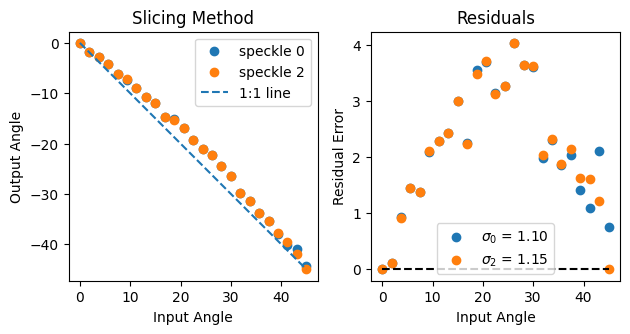

In [153]:
oneoneline = -input_angles
resids0 = output_angles0 - oneoneline
resids2 = output_angles2 - oneoneline
sd0 = np.std(resids0)
sd2 = np.std(resids2)

fig, ax = plt.subplots(1,2)

ax[0].scatter(input_angles,output_angles0,label='speckle 0')
ax[0].scatter(input_angles,output_angles2,label='speckle 2')
ax[0].plot(input_angles,-input_angles,'--',label='1:1 line')
ax[0].set_box_aspect(1)
ax[0].set_ylabel('Output Angle')
ax[0].set_xlabel('Input Angle')
ax[0].set_title('Slicing Method')
#ax[0].set_ylim((45,90))
ax[0].legend()

ax[1].scatter(input_angles,resids0,label=fr'$\sigma_0$ = {sd0:.2f}')
ax[1].scatter(input_angles,resids2,label=fr'$\sigma_2$ = {sd2:.2f}')
ax[1].hlines(0,input_angles[0],input_angles[-1],color='black',linestyle='dashed')
plt.title('Residuals')
ax[1].set_xlabel('Input Angle')
ax[1].set_ylabel('Residual Error')
ax[1].set_box_aspect(1)
ax[1].legend()
fig.tight_layout()

# ax[1].scatter(input_angles,output_offsets)
# ax[1].hlines(0,0,45,linestyle='dashed',color='black')
# ax[1].set_xlabel('Input Angle')
# ax[1].set_ylabel('Pair Offset Angle')
# ax[1].set_ylim((-2,2))
# ax[1].set_box_aspect(1)

fig.tight_layout()

I'm really curious what this plot looks like with the previous algorithm.

now let's test the other way of doing the pair offset calculations, the way that doesn't wrap things around by assuming small angles and using the geometric definition of a cross product.

In [154]:
#let's plot the pair offsets using the subtraction method vs the vector method
input_angles = np.linspace(0,45,25)
offset = np.zeros_like(input_angles)


for i, angle in enumerate(input_angles):
    img = psf(wavelength, bandwidth, dispersion_y=disp_y, angle=angle, freq=f)
    cropped = crop_image(img,200,mask_diam=0.5E-6)
    
    speckle0 = speckle_cutout(cropped,1,angle=angle)
    speckle2 = speckle_cutout(cropped,3,angle=angle)

    xcoords0, ycoords0 = speckle_angle(speckle0,'horizontal',threshold_ratio=0.3,core_ratio=0.1)
    xcoords2, ycoords2 = speckle_angle(speckle2,'horizontal',threshold_ratio=0.3,core_ratio=0.1)

    pointing_x0,pointing_y0 = spot_direction(xcoords0,ycoords0)
    pointing_x2,pointing_y2 = spot_direction(xcoords2,ycoords2)

    pointing0 = np.array([pointing_x0,pointing_y0])
    pointing2 = np.array([pointing_x2,pointing_y2])

    offset[i] = np.degrees(pair_offset(pointing0,pointing2))

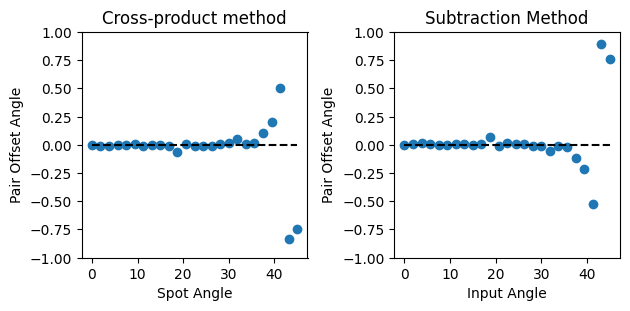

In [155]:
fig, ax = plt.subplots(1,2)

ax[0].scatter(input_angles,offset)
ax[0].hlines(0,0,45,linestyle='dashed',color='black')
ax[0].set_xlabel('Spot Angle')
ax[0].set_ylabel('Pair Offset Angle')
ax[0].set_title('Cross-product method')
ax[0].set_ylim(-1,1)
ax[0].set_box_aspect(1)

ax[1].scatter(input_angles,output_offsets)
ax[1].hlines(0,0,45,linestyle='dashed',color='black')
ax[1].set_xlabel('Input Angle')
ax[1].set_ylabel('Pair Offset Angle')
ax[1].set_title('Subtraction Method')
ax[1].set_ylim((-1,1))
ax[1].set_box_aspect(1)

fig.tight_layout()

### testing to see if the bias affects the offset measurement at different angles

In [156]:
input_angles = np.linspace(0,45,25)
angle_offset = 5
output_angles0 = np.zeros_like(input_angles)
output_angles2 = np.zeros_like(input_angles)
offset = np.zeros_like(input_angles)

f = 15

for i, angle in enumerate(input_angles):
    img0 = psf(wavelength, bandwidth, dispersion_y=disp_y, angle=angle, freq=f)
    img2 = psf(wavelength, bandwidth, dispersion_y=disp_y, angle=angle - angle_offset, freq=f)
    cropped0 = crop_image(img0,200,mask_diam=0.5E-6)
    cropped2 = crop_image(img2,200,mask_diam=0.5E-6)
    
    speckle0 = speckle_cutout(cropped0,0,angle=angle)
    speckle2 = speckle_cutout(cropped2,2,angle=angle)

    xcoords0, ycoords0 = speckle_angle(speckle0,'vertical',threshold_ratio=0.3,core_ratio=0.1)
    xcoords2, ycoords2 = speckle_angle(speckle2,'vertical',threshold_ratio=0.3,core_ratio=0.1)

    #i'm not sure that this is the correct solution to the projection effect problem! but it seems to improve things so we're leaving it in for now
    # if angle != 0:
    #     xcoords0 = xcoords0 * np.cos(np.radians(angle))
    #     xcoords2 = xcoords2 * np.cos(np.radians(angle))

    pointing_x0,pointing_y0 = spot_direction(xcoords0,ycoords0)
    angle0 = np.atan2(pointing_y0,pointing_x0)

    pointing_x2,pointing_y2 = spot_direction(xcoords2,ycoords2)
    angle2 = np.atan2(pointing_y2,pointing_x2)

    output_angles0[i] = np.degrees(angle0)
    output_angles2[i] = np.degrees(angle2)

    pointing0 = np.array([pointing_x0,pointing_y0])
    pointing2 = np.array([pointing_x2,pointing_y2])

    offset[i] = np.degrees(pair_offset(pointing0,pointing2))

output_offsets = output_angles0 - output_angles2

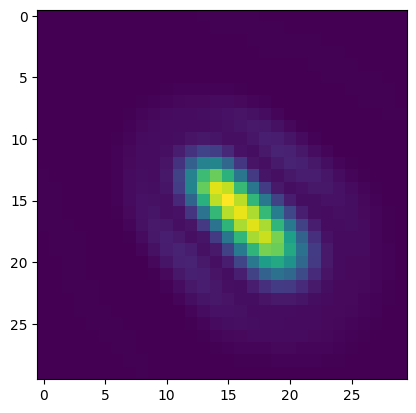

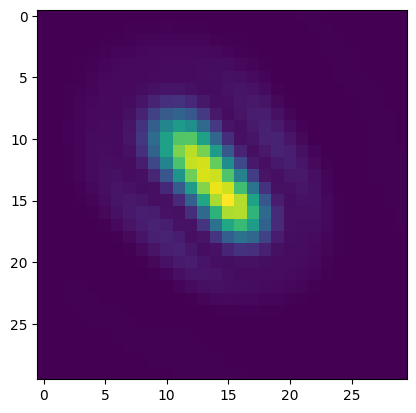

In [157]:
plt.imshow(speckle0)
plt.figure()
plt.imshow(speckle2)

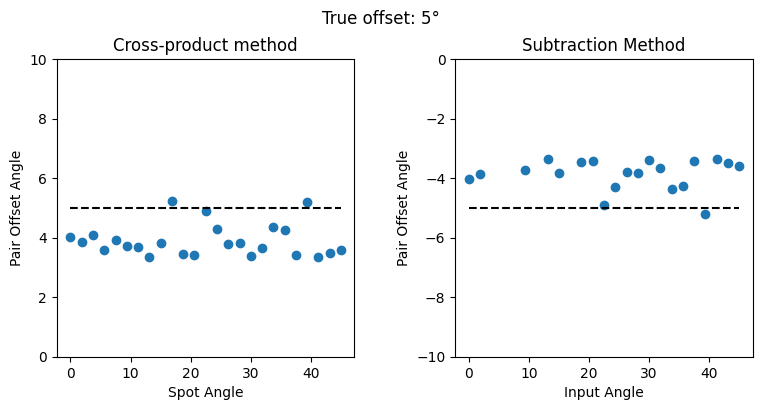

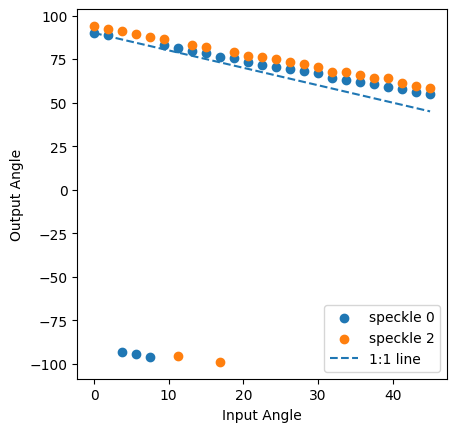

In [158]:
fig, ax = plt.subplots(1,2,figsize=(8,4))
fig.suptitle(f'True offset: {angle_offset}°')

ax[0].scatter(input_angles,offset)
ax[0].hlines(angle_offset,0,45,linestyle='dashed',color='black')
ax[0].set_xlabel('Spot Angle')
ax[0].set_ylabel('Pair Offset Angle')
ax[0].set_title('Cross-product method')
ax[0].set_ylim(angle_offset-5,angle_offset+5)
ax[0].set_box_aspect(1)

ax[1].scatter(input_angles,output_offsets)
ax[1].hlines(-angle_offset,0,45,linestyle='dashed',color='black')
ax[1].set_xlabel('Input Angle')
ax[1].set_ylabel('Pair Offset Angle')
ax[1].set_title('Subtraction Method')
ax[1].set_ylim(-angle_offset-5,-angle_offset+5)
ax[1].set_box_aspect(1)

fig.tight_layout()

fig, ax = plt.subplots(1)

ax.scatter(input_angles,output_angles0,label='speckle 0')
ax.scatter(input_angles,output_angles2,label='speckle 2')
ax.plot(input_angles,90-input_angles,'--',label='1:1 line')
ax.set_box_aspect(1)
ax.set_ylabel('Output Angle')
ax.set_xlabel('Input Angle')
#ax.set_ylim((45,90))
ax.legend()

this method of finding the pointing angle is definitely biased, and probably not in a way that can be solved. the only way this method works is if the spot's major axis is orthogonal to the cross-section axis, which it will never be unless there is zero dispersion (and we know the satellite spot orientations very precisely, which we might not). we might have to change entirely the way that the fitting is happening, going back to the method of moments and adapting it to deal with the types of noise that we get in these images.

### Method of Moments

this method weights things more heavily if they are further away from the center, which is good in terms of the 'lever arm' effect to determine the pointing direction of the image, but which also amplifies both white and structured noise that aren't contributing to the actual satellite spot signal.

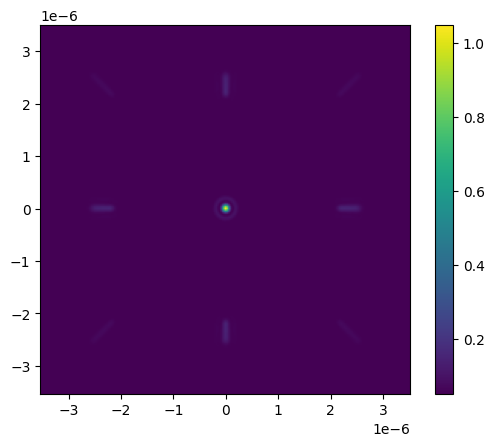

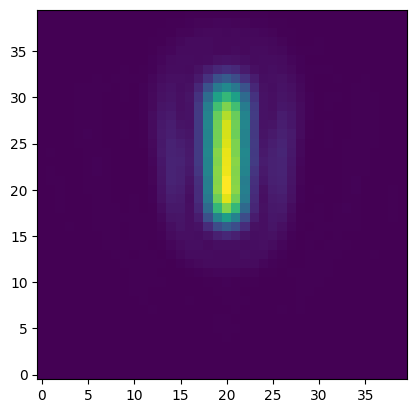

In [159]:
f = 20
angle=0
sigma_readout = 0.00001 #everything breaks if this is zero! 
bias = 0.05
n_photons = 1E7

bb_psf = poisson_psf(wavelength,bandwidth,num_photons=n_photons,angle=angle,freq=f)
background = Field(np.random.normal(0, sigma_readout, size=bb_psf.shaped.size)+bias,bb_psf.grid)
bb_psf_noisy = bb_psf/bb_psf.max() + background
cropped = crop_image(bb_psf_noisy,200,mask_diam=0)
speckle0 = speckle_cutout(cropped,0,angle,f,window_size=40)
imshow_field(bb_psf_noisy)
plt.colorbar()
plt.figure()
plt.imshow(speckle0,origin='lower')

0.00011375465263146938
7.672646204739605e-05
est bkgnd: 0.05013405238391454
max SNR: 834.3313452003347


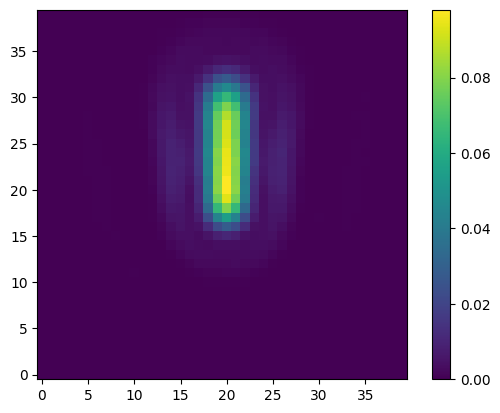

In [160]:
#try it first outside of a function
crop_pos = np.maximum(speckle0.astype(np.float64), 0.0)
ny, nx = crop_pos.shape
y_grid, x_grid = np.mgrid[0:ny, 0:nx]

# 1. Estimate Residual Noise Floor on positive-floored signal
border_pixels = np.concatenate(
    [
        crop_pos[0, :],
        crop_pos[-1, :],
        crop_pos[:, 0],
        crop_pos[:, -1],
    ]
)

# Estimate noise level using robust MAD on non-zero background
bg_level = np.median(border_pixels)
mad = np.median(np.abs(border_pixels - bg_level))
sigma_noise = 1.4826 * mad if mad > 0 else 1

# 2a. Subtract residual local background and re-enforce non-negativity
img_sub = np.maximum(crop_pos - bg_level, 0.0)

# 2b. Smooth to find initial 2D Peak & Estimate Peak SNR
fwhm_px = 6 #tunable parameter

sigma_smooth = fwhm_px / 2.355
smoothed = ndimage.gaussian_filter(np.maximum(img_sub, 0.0), sigma=sigma_smooth)
peak_y, peak_x = np.unravel_index(np.argmax(smoothed), smoothed.shape)
peak_val = img_sub[peak_y, peak_x]

snr_est = peak_val / sigma_noise if sigma_noise > 0 else 100.0

plt.imshow(img_sub,origin='lower')
plt.colorbar()
print(sigma_noise)
print(mad)
print(f'est bkgnd: {bg_level}')
print(f'max SNR: {snr_est}')

In [161]:
# 3. Dynamic SNR Adjustments
if snr_est < 15.0:
    # Low SNR regime (5-15): Aggressive noise cut, tight window
    snr_thresh_factor = 2.5
    min_win_scale = 0.8
    max_win_scale = 1.2
elif snr_est < 50.0:
    # Mid SNR regime (15-50): Balanced settings
    snr_thresh_factor = 1.5
    min_win_scale = 0.8
    max_win_scale = 1.8
else:
    # High SNR regime (>50): Relaxed threshold, wide window for accuracy
    snr_thresh_factor = 1.0
    min_win_scale = 1.0
    max_win_scale = 2.5

# Threshold image based on estimated SNR
img_clean = np.maximum(
    img_sub - (snr_thresh_factor * sigma_noise), 0.0
)

# Initial state
x_bar, y_bar = float(peak_x), float(peak_y)
angle = 0.0
sigma_u = fwhm_px * 0.5
sigma_v = fwhm_px * 0.5

# 4. Iterative Moment Computation
max_iter = 10
tol_deg = 0.01

for iteration in range(max_iter):
    prev_angle = angle

    dx = x_grid - x_bar
    dy = y_grid - y_bar

    # Check centroid drift: Don't let iteration drift > 1 FWHM from smoothed peak
    dist_from_peak = np.sqrt((x_bar - peak_x) ** 2 + (y_bar - peak_y) ** 2)
    if dist_from_peak > fwhm_px:
        x_bar, y_bar = float(peak_x), float(peak_y)
        dx = x_grid - x_bar
        dy = y_grid - y_bar

    # Rotate to principal axis frame
    cos_a, sin_a = np.cos(angle), np.sin(angle)
    u = dx * cos_a + dy * sin_a
    v = -dx * sin_a + dy * cos_a

    # Soft Elliptical Gaussian Window
    window = np.exp(-0.5 * ((u / sigma_u) ** 2 + (v / sigma_v) ** 2))
    weights = img_clean * window
    total_weight = np.sum(weights)

    # if total_weight == 0:
    #     # Fallback for extreme noise: use raw peak-centered unweighted moments
    #     weights = np.maximum(img_clean, 0.0)
    #     total_weight = np.sum(weights)
    #     if total_weight == 0:
    #         return 0.0

    # Refine Centroid
    x_bar = np.sum(x_grid * weights) / total_weight
    y_bar = np.sum(y_grid * weights) / total_weight

    # Compute 2nd Central Moments
    dx_c = x_grid - x_bar
    dy_c = y_grid - y_bar

    mu20 = np.sum((dx_c**2) * weights)
    mu02 = np.sum((dy_c**2) * weights)
    mu11 = np.sum((dx_c * dy_c) * weights)

    # Unbiased Angle Calculation
    angle = 0.5 * np.arctan2(2 * mu11, mu20 - mu02)

    # Calculate shape variances
    var_u = 0.5 * (
        mu20 + mu02 + np.sqrt((mu20 - mu02) ** 2 + 4 * (mu11**2))
    )
    var_v = 0.5 * (
        mu20 + mu02 - np.sqrt((mu20 - mu02) ** 2 + 4 * (mu11**2))
    )

    # Adaptively update window dimensions with SNR-based bounds
    raw_sigma_u = np.sqrt(max(var_u / total_weight, 0.25))
    raw_sigma_v = np.sqrt(max(var_v / total_weight, 0.25))

    sigma_u = np.clip(
        raw_sigma_u, min_win_scale * fwhm_px, max_win_scale * fwhm_px
    )
    sigma_v = np.clip(
        raw_sigma_v, min_win_scale * fwhm_px, max_win_scale * fwhm_px
    )

    # Check convergence
    if (
        np.abs(np.degrees(angle - prev_angle)) < tol_deg
        and iteration > 0
    ):
        break

In [162]:
print(np.degrees(angle))
print(iteration)

-89.96704187473412
1


In [163]:
#code for new method of moments
def moment_angle(
    crop: np.ndarray,
    fwhm_px: float = 6.0,
    max_iter: int = 5,
    tol_deg: float = 0.05,
) -> float:

    # 0. Physical Positivity Enforcer (Fix for pre-subtracted negative pixels)
    # Floor raw input to zero immediately so negative background noise cannot act as "negative mass"
    crop_pos = np.maximum(crop.astype(np.float64), 0.0)
    ny, nx = crop_pos.shape
    y_grid, x_grid = np.mgrid[0:ny, 0:nx]

    # 1. Estimate Residual Noise Floor on positive-floored signal
    border_pixels = np.concatenate(
        [
            crop_pos[0, :],
            crop_pos[-1, :],
            crop_pos[:, 0],
            crop_pos[:, -1],
        ]
    )

    # Estimate noise level using robust MAD on non-zero background
    bg_level = np.median(border_pixels)
    mad = np.median(np.abs(border_pixels - bg_level))
    sigma_noise = 1.4826 * mad if mad > 0 else 1

    # 2. Subtract residual local background and re-enforce non-negativity
    img_sub = np.maximum(crop_pos - bg_level, 0.0)

    # 2. Smooth to find initial 2D Peak & Estimate Peak SNR
    sigma_smooth = fwhm_px / 2.355
    smoothed = ndimage.gaussian_filter(np.maximum(img_sub, 0.0), sigma=sigma_smooth)
    peak_y, peak_x = np.unravel_index(np.argmax(smoothed), smoothed.shape)
    peak_val = img_sub[peak_y, peak_x]

    snr_est = peak_val / sigma_noise if sigma_noise > 0 else 100.0

    # 3. Dynamic SNR Adjustments
    if snr_est < 15.0:
        # Low SNR regime (5-15): Aggressive noise cut, tight window
        snr_thresh_factor = 2.5
        min_win_scale = 0.8
        max_win_scale = 1.2
    elif snr_est < 50.0:
        # Mid SNR regime (15-50): Balanced settings
        snr_thresh_factor = 1.5
        min_win_scale = 0.8
        max_win_scale = 1.8
    else:
        # High SNR regime (>50): Relaxed threshold, wide window for accuracy
        snr_thresh_factor = 1.0
        min_win_scale = 1.0
        max_win_scale = 2.5

    # Threshold image based on estimated SNR
    img_clean = np.maximum(
        img_sub - (snr_thresh_factor * sigma_noise), 0.0
    )

    # Initial state
    x_bar, y_bar = float(peak_x), float(peak_y)
    angle = 0.0
    sigma_u = fwhm_px * 0.5
    sigma_v = fwhm_px * 0.5

    # 4. Iterative Moment Computation
    for iteration in range(max_iter):
        prev_angle = angle

        dx = x_grid - x_bar
        dy = y_grid - y_bar

        # Check centroid drift: Don't let iteration drift > 1 FWHM from smoothed peak
        dist_from_peak = np.sqrt((x_bar - peak_x) ** 2 + (y_bar - peak_y) ** 2)
        if dist_from_peak > fwhm_px:
            x_bar, y_bar = float(peak_x), float(peak_y)
            dx = x_grid - x_bar
            dy = y_grid - y_bar

        # Rotate to principal axis frame
        cos_a, sin_a = np.cos(angle), np.sin(angle)
        u = dx * cos_a + dy * sin_a
        v = -dx * sin_a + dy * cos_a

        # Soft Elliptical Gaussian Window
        window = np.exp(-0.5 * ((u / sigma_u) ** 2 + (v / sigma_v) ** 2))
        weights = img_clean * window
        total_weight = np.sum(weights)

        if total_weight == 0:
            # Fallback for extreme noise: use raw peak-centered unweighted moments
            weights = np.maximum(img_clean, 0.0)
            total_weight = np.sum(weights)
            if total_weight == 0:
                return 0.0

        # Refine Centroid
        x_bar = np.sum(x_grid * weights) / total_weight
        y_bar = np.sum(y_grid * weights) / total_weight

        # Compute 2nd Central Moments
        dx_c = x_grid - x_bar
        dy_c = y_grid - y_bar

        mu20 = np.sum((dx_c**2) * weights)
        mu02 = np.sum((dy_c**2) * weights)
        mu11 = np.sum((dx_c * dy_c) * weights)

        # Unbiased Angle Calculation
        angle = 0.5 * np.arctan2(2 * mu11, mu20 - mu02)

        # Calculate shape variances
        var_u = 0.5 * (
            mu20 + mu02 + np.sqrt((mu20 - mu02) ** 2 + 4 * (mu11**2))
        )
        var_v = 0.5 * (
            mu20 + mu02 - np.sqrt((mu20 - mu02) ** 2 + 4 * (mu11**2))
        )

        # Adaptively update window dimensions with SNR-based bounds
        raw_sigma_u = np.sqrt(max(var_u / total_weight, 0.25))
        raw_sigma_v = np.sqrt(max(var_v / total_weight, 0.25))

        sigma_u = np.clip(
            raw_sigma_u, min_win_scale * fwhm_px, max_win_scale * fwhm_px
        )
        sigma_v = np.clip(
            raw_sigma_v, min_win_scale * fwhm_px, max_win_scale * fwhm_px
        )

        # Check convergence
        if (
            np.abs(np.degrees(angle - prev_angle)) < tol_deg
            and iteration > 0
        ):
            break

    return float(np.degrees(angle))

In [164]:
f = 20
angle=0
sigma_readout = 0.0001 #everything breaks if this is zero! 
bias = 0.05
n_photons = 1E7

bb_psf = poisson_psf(wavelength,bandwidth,num_photons=n_photons,angle=angle,freq=f)
background = Field(np.random.normal(0, sigma_readout, size=bb_psf.shaped.size)+bias,bb_psf.grid)
bb_psf_noisy = bb_psf/bb_psf.max() + background
cropped = crop_image(bb_psf_noisy,200,mask_diam=0)
speckle0 = speckle_cutout(cropped,0,angle,f,window_size=30)

In [165]:
speckle_angle = moment_angle(speckle0)
print(f'speckle angle: {speckle_angle}')

speckle angle: 89.96203625156498


the  new method should be tested for a few things. first off, we should make sure there's no bias. Then we should explore the effects of satellite spot separation. Shot noise and background noise should also be analyzed, but not sure we need to do it right now, since these are still absolute angles rather than pair offsets which can be directly linked to a dispersion value.

In [166]:
#same procedure as before where we test for bias based on diffraction angle
input_angles = np.linspace(1,90,50)
output_angles0 = np.zeros_like(input_angles)
output_angles2 = np.zeros_like(input_angles)

f = 20
angle=0
sigma_readout = 0.001 #everything breaks if this is zero! 
bias = 0.05
n_photons = 1E7

for i, angle in enumerate(input_angles):
    bb_psf = poisson_psf(wavelength,bandwidth,num_photons=n_photons,angle=angle,freq=f)
    background = Field(np.random.normal(0, sigma_readout, size=bb_psf.shaped.size)+bias,bb_psf.grid)
    bb_psf_noisy = bb_psf/bb_psf.max() + background
    cropped = crop_image(bb_psf_noisy,200,mask_diam=0)
    speckle0 = speckle_cutout(cropped,0,angle,f,window_size=40)
    speckle2 = speckle_cutout(cropped,2,angle,f,window_size=40)

    angle0 = moment_angle(speckle0)
    angle2 = moment_angle(speckle2)

    output_angles0[i] = angle0
    output_angles2[i] = angle2

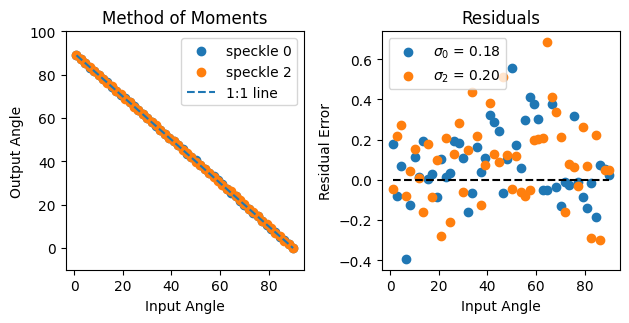

In [167]:
fig, ax = plt.subplots(1,2)

oneoneline = 90 - input_angles
resids0 = output_angles0 - oneoneline
resids2 = output_angles2 - oneoneline
sd0 = np.std(resids0)
sd2 = np.std(resids2)

ax[0].scatter(input_angles,output_angles0,label='speckle 0')
ax[0].scatter(input_angles,output_angles2,label='speckle 2')
ax[0].plot(input_angles,90-input_angles,'--',label='1:1 line')
ax[0].set_box_aspect(1)
ax[0].set_ylim((-10,100))
ax[0].set_ylabel('Output Angle')
ax[0].set_xlabel('Input Angle')
ax[0].set_title('Method of Moments')
ax[0].legend()

ax[1].scatter(input_angles,resids0,label=fr'$\sigma_0$ = {sd0:.2f}')
ax[1].scatter(input_angles,resids2,label=fr'$\sigma_2$ = {sd2:.2f}')
ax[1].hlines(0,input_angles[0],input_angles[-1],color='black',linestyle='dashed')
plt.title('Residuals')
ax[1].set_xlabel('Input Angle')
ax[1].set_ylabel('Residual Error')
ax[1].set_box_aspect(1)
ax[1].legend()
fig.tight_layout()


this level of precision is really close to the 0.1° precision that we want, which means it will take far fewer samples than we've had to take in the past to achieve the desired precision.

### FWHM vs. Satellite Spot methods
now that we have a reliable way of measuring the satellite spot orientation, let's see if the spots rotate at the same rate that the FWHM elongates.

In [168]:
wavelength = 764E-9
bandwidth = 126E-9
angle = 90
sigma_readout = 0.001

disps = np.linspace(0,3,50)
fwhms = np.zeros_like(disps)
output_angles0 = np.zeros_like(disps)
output_angles2 = np.zeros_like(disps)

for i,disp_y in enumerate(disps):
    dispersed_psf = poisson_psf(wavelength,bandwidth,num_photons = 1E9,angle=angle,dispersion_y = disp_y)
    
    #fwhm measurement
    fwhms[i] = psf_vertical_fwhm(dispersed_psf.copy()) * pix_size_mas[0]

    #satellite spot measurement (needs a little bit of noise to work)
    background = Field(np.random.normal(0, sigma_readout, size=dispersed_psf.shaped.size)+bias,dispersed_psf.grid)
    dispersed_psf_noisy = dispersed_psf/dispersed_psf.max() + background
    cropped = crop_image(dispersed_psf_noisy,220,mask_diam=0)
    speckle0 = speckle_cutout(cropped,0,angle,f,window_size=30)
    speckle2 = speckle_cutout(cropped,2,angle,f,window_size=30)

    angle0 = moment_angle(speckle0)
    angle2 = moment_angle(speckle2)

    output_angles0[i] = angle0
    output_angles2[i] = angle2


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_83414/3911180894.py:3: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


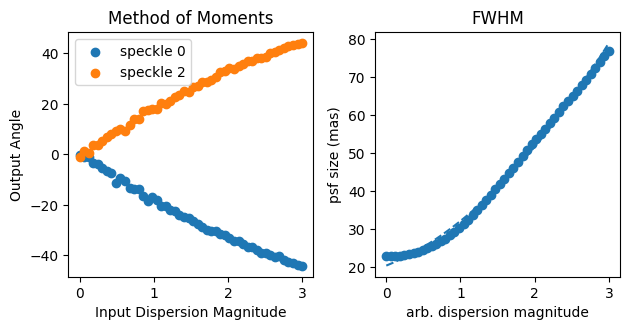

In [169]:
line = np.polyfit(disps,fwhms,2)
p = np.poly1d(line)

fig, ax = plt.subplots(1,2)

ax[0].scatter(disps,output_angles0,label='speckle 0')
ax[0].scatter(disps,output_angles2,label='speckle 2')
ax[0].set_box_aspect(1)
ax[0].set_ylabel('Output Angle')
ax[0].set_xlabel('Input Dispersion Magnitude')
ax[0].set_title('Method of Moments')
ax[0].legend()

ax[1].scatter(disps,fwhms)
ax[1].plot(disps, p(disps),'--')
ax[1].set_xlabel('arb. dispersion magnitude')
ax[1].set_ylabel('psf size (mas)')
ax[1].set_title('FWHM')
ax[1].set_box_aspect(1)

fig.tight_layout()

### Photon noise limitations
Let's explore what happens to each method when we start giving fewer and fewer photons of signal. The figure of merit here will be the standard deviation of the residuals. we will use a set of fixed sparkles/DM spots, generate a PSF with random poisson noise given a certain number of photons, and analyze the average residual over a number of trials. We will do this for different numbers of photons.

In [172]:
from adc_algo import *

#new window/cropping functions to get rid of that one error
def window_field(data, center, width, height, pad_value=0.0):
    # 1. Find nearest pixel index for target center
    indx = data.grid.closest_to(center)
    ny_in, nx_in = data.shaped.shape
    y_ind, x_ind = np.unravel_index(indx, (ny_in, nx_in))

    # 2. Compute ideal slice bounds
    x_min_ideal = x_ind - width // 2
    x_max_ideal = x_min_ideal + width
    y_min_ideal = y_ind - height // 2
    y_max_ideal = y_min_ideal + height

    # 3. Clamp bounds to valid image indices
    x_min_valid = max(0, x_min_ideal)
    x_max_valid = min(nx_in, x_max_ideal)
    y_min_valid = max(0, y_min_ideal)
    y_max_valid = min(ny_in, y_max_ideal)

    # 4. Map valid patch into output array
    out_x_min = x_min_valid - x_min_ideal
    out_x_max = out_x_min + (x_max_valid - x_min_valid)
    out_y_min = y_min_valid - y_min_ideal
    out_y_max = out_y_min + (y_max_valid - y_min_valid)

    # 5. Allocate output crop array filled with pad_value
    cutout = np.full((height, width), pad_value, dtype=data.shaped.dtype)

    if (x_max_valid > x_min_valid) and (y_max_valid > y_min_valid):
        cutout[out_y_min:out_y_max, out_x_min:out_x_max] = data.shaped[
            y_min_valid:y_max_valid, x_min_valid:x_max_valid
        ]

    # 6. Construct sub_grid matching original syntax, shifted to center
    dx = data.grid.delta[0]
    dy = data.grid.delta[1]
    sub_grid = make_pupil_grid([width, height], [width * dx, height * dy])

    return Field(cutout.ravel(), sub_grid)

def crop_image(image, extent=100, mask_diam=0.5e-6):
    """Cuts out a centered PSF with the central core masked."""
    img_max = np.max(image)
    if img_max > 0:
        img_normalized = image / img_max
    else:
        img_normalized = image

    img_subtracted = img_normalized > 0.1
    total_sig = np.sum(img_subtracted)

    if total_sig > 0:
        center_of_intensity = np.array([
            np.sum(img_subtracted * img_subtracted.grid.x) / total_sig,
            np.sum(img_subtracted * img_subtracted.grid.y) / total_sig,
        ])
    else:
        center_of_intensity = np.array([0.0, 0.0])

    # Mask central core
    mask_ap = make_circular_aperture(mask_diam, center_of_intensity)
    mask = np.abs(mask_ap(img_subtracted.grid) - 1.0)
    image = mask * image

    # Safe padded crop
    image = window_field(image, center_of_intensity, extent, extent)

    # Vectorised non-negativity floor
    return np.maximum(image, 0.0)

In [188]:
n_photons = np.logspace(3,10,8)
angles0_photons = []
angles2_photons = []
angles0_photons_slice = []
angles2_photons_slice = []

n_trials = 20


f = 20
angle=85
sigma_readout = 0.0001 #everything breaks if this is zero! 
bias = 0.0

for i,n in enumerate(n_photons):
    angles0 = np.zeros(n_trials)
    angles2 = np.zeros_like(angles0)
    angles0_slice = np.zeros_like(angles0)
    angles2_slice = np.zeros_like(angles2)

    for j in range(n_trials):
        bb_psf = poisson_psf(wavelength,bandwidth,num_photons=n,angle=angle,freq=f)

        background = Field(np.random.normal(0, sigma_readout, size=bb_psf.shaped.size)+bias,bb_psf.grid)
        bb_psf_noisy = bb_psf/bb_psf.max() + background
        cropped = crop_image(bb_psf_noisy,200,mask_diam=0)
        speckle0 = speckle_cutout(cropped,0,angle,f,window_size=30)
        speckle2 = speckle_cutout(cropped,2,angle,f,window_size=30)

        #moment method
        angle0 = moment_angle(speckle0)
        angle2 = moment_angle(speckle2)

        angles0[j] = angle0
        angles2[j] = angle2

        #slicing method
        xcoords0, ycoords0 = speckle_angle(speckle0,'horizontal',threshold_ratio=0.3,core_ratio=0.1)
        xcoords2, ycoords2 = speckle_angle(speckle2,'horizontal',threshold_ratio=0.3,core_ratio=0.1)

        pointing_x0,pointing_y0 = spot_direction(xcoords0,ycoords0)
        pointing_x2,pointing_y2 = spot_direction(xcoords2,ycoords2)
        
        angle0 = np.atan2(pointing_y0,pointing_x0)
        angle2 = np.atan2(pointing_y2,pointing_x2)

        angles0_slice[j] = np.degrees(angle0)
        angles2_slice[j] = np.degrees(angle2)

    angles0_photons.append(angles0)
    angles2_photons.append(angles2)
    angles0_photons_slice.append(angles0_slice)
    angles2_photons_slice.append(angles2_slice)

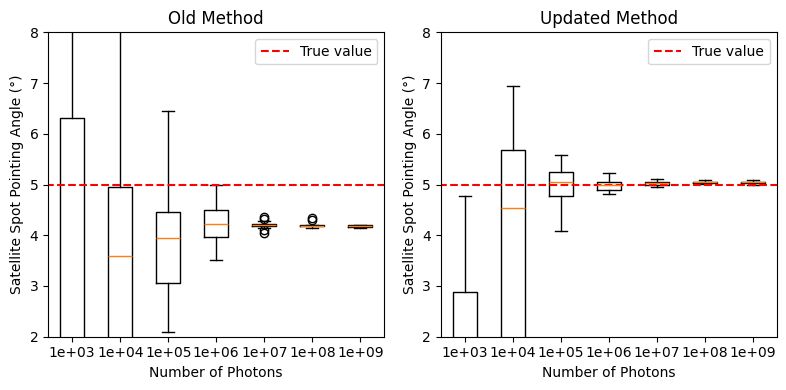

In [210]:
n_photons_label = [f'{i:.0e}' for i in np.array(n_photons)]

plt.figure(figsize=(8,4))
plt.subplot(1,2,2)
plt.boxplot(angles0_photons,tick_labels=n_photons_label)
plt.hlines(5,0,8,'red','dashed',label='True value')
plt.xlim((0.5,7.5))
plt.ylim((2,8))
plt.title('Updated Method')
plt.xlabel('Number of Photons')
plt.ylabel('Satellite Spot Pointing Angle (°)')
plt.legend()

plt.subplot(1,2,1)
plt.boxplot(angles0_photons_slice,tick_labels=n_photons_label)
plt.hlines(5,0,8,'red','dashed',label='True value')
plt.xlim((0.5,7.5))
plt.ylim((2,8))
plt.xlabel('Number of Photons')
plt.ylabel('Satellite Spot Pointing Angle (°)')
plt.title('Old Method')
plt.legend()

plt.tight_layout()
plt.show()


### Testing the  New Method with Low SNR
combination of photon noise + higher readout/gaussian noise. I don't think I'll put residual turbulence noise in here, mostly because that sounds hard.

In [238]:
n_photons = np.logspace(3,10,8)
readout_noise = np.logspace(-5,-1,5)

angles0_photons = []
angles2_photons = []
angles0_photons_slice = []
angles2_photons_slice = []

angles0_noiselevels = []
angles2_noiselevels = []
angles0_noiselevels_slice = []
angles2_noiselevels_slice = []

n_trials = 5
f = 20
angle=85
bias = 0.01

for s, sigma_readout in enumerate(readout_noise):
    angles0_photons = []
    angles2_photons = []
    angles0_photons_slice = []
    angles2_photons_slice = []

    #given that amount of noise, run the simulation at a variety of different photon levels and get the results over N trials
    for i,n in enumerate(n_photons):
        angles0 = np.zeros(n_trials)
        angles2 = np.zeros_like(angles0)
        angles0_slice = np.zeros_like(angles0)
        angles2_slice = np.zeros_like(angles2)

        for j in range(n_trials):
            bb_psf = poisson_psf(wavelength,bandwidth,num_photons=n,angle=angle,freq=f)

            background = Field(np.random.normal(0, sigma_readout, size=bb_psf.shaped.size)+bias,bb_psf.grid)
            bb_psf_noisy = bb_psf/bb_psf.max() + background
            cropped = crop_image(bb_psf_noisy,200,mask_diam=0)
            speckle0 = speckle_cutout(cropped,0,angle,f,window_size=30)
            speckle2 = speckle_cutout(cropped,2,angle,f,window_size=30)

            #moment method
            angle0 = moment_angle(speckle0)
            angle2 = moment_angle(speckle2)

            angles0[j] = angle0
            angles2[j] = angle2

            #slicing method
            xcoords0, ycoords0 = speckle_angle(speckle0,'horizontal',threshold_ratio=0.3,core_ratio=0.1)
            xcoords2, ycoords2 = speckle_angle(speckle2,'horizontal',threshold_ratio=0.3,core_ratio=0.1)

            pointing_x0,pointing_y0 = spot_direction(xcoords0,ycoords0)
            pointing_x2,pointing_y2 = spot_direction(xcoords2,ycoords2)
            
            angle0 = np.atan2(pointing_y0,pointing_x0)
            angle2 = np.atan2(pointing_y2,pointing_x2)

            angles0_slice[j] = np.degrees(angle0)
            angles2_slice[j] = np.degrees(angle2)

        angles0_photons.append(angles0)
        angles2_photons.append(angles2)
        angles0_photons_slice.append(angles0_slice)
        angles2_photons_slice.append(angles2_slice)

    #now each element of these lists is a set of box plots at different photon noise levels
    angles0_noiselevels.append(angles0_photons)
    angles2_noiselevels.append(angles2_photons)
    angles0_noiselevels_slice.append(angles0_photons_slice)
    angles2_noiselevels_slice.append(angles2_photons_slice)


In [239]:
print(readout_noise)

[1.e-05 1.e-04 1.e-03 1.e-02 1.e-01]


In [264]:
#boxplot function so that i can change the color

def box_plot(data, color,label):
    bp = plt.boxplot(data,patch_artist=True,label=label)
    
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=color)

    for patch in bp['boxes']:
        patch.set(facecolor=color,alpha=0.4)       
        
    return bp

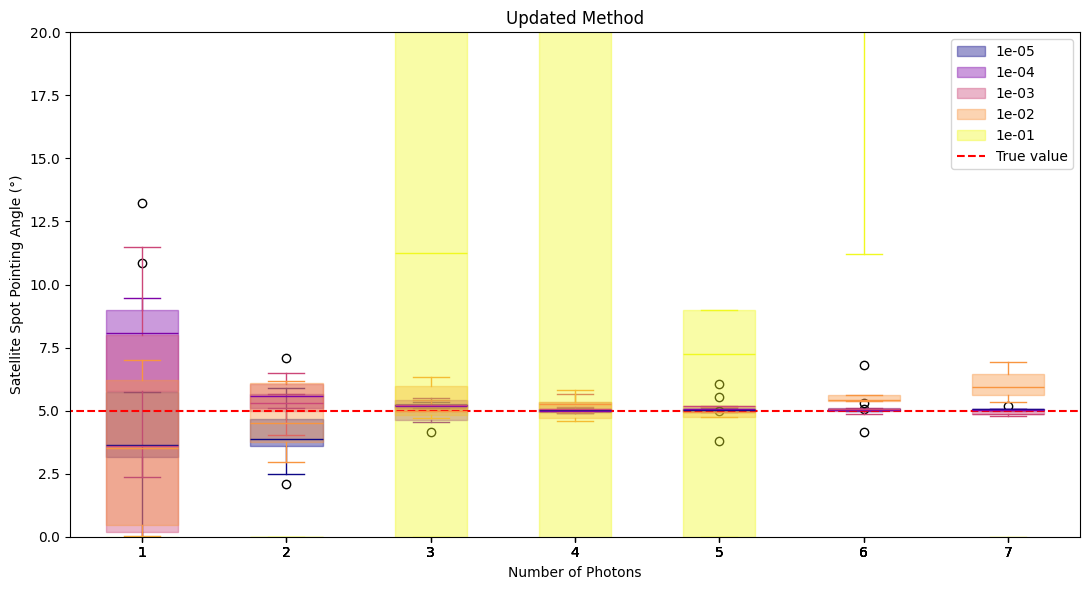

In [268]:
n_photons_label = [f'{i:.0e}' for i in np.array(n_photons)]
sigma_noise_label = [f'{i:.0e}' for i in np.array(readout_noise)]
cmap = plt.colormaps['plasma']
colors = cmap(np.linspace(0, 1, len(sigma_noise_label)))

plt.figure(figsize=(11,6))
#plt.subplot(1,2,2)
for i in range(len(sigma_noise_label)):

    a = angles0_noiselevels[i]
    b = angles0_noiselevels_slice[i]

    bp1 = box_plot(a,color=colors[i],label=sigma_noise_label[i])

plt.hlines(5,0,8,'red','dashed',label='True value')
plt.xlim((0.5,7.5))
plt.ylim((0,20))
plt.title(fr'Updated Method')
plt.xlabel('Number of Photons')
plt.ylabel('Satellite Spot Pointing Angle (°)')
plt.legend()

## do the same for the old method
# plt.subplot(1,2,1)
# plt.boxplot(b,tick_labels=n_photons_label)
# plt.hlines(5,0,8,'red','dashed',label='True value')
# plt.xlim((0.5,7.5))
# #plt.ylim((2,8))
# plt.xlabel('Number of Photons')
# plt.ylabel('Satellite Spot Pointing Angle (°)')
# plt.title('Old Method')
# plt.legend()

plt.tight_layout()
plt.show()


^^ this plot is a mess, and i don't feel like fixing it, but it contains all the right information (just in a way that's pretty unreadable). what i should do is make one subplot for each read noise value, but i will spare myself that for now. if this becomes important, I'll come back and finish it. the important part is that, as we expect, the noise impacts our ability to get an accurate measurement, especially at lower photon levels. Also importantly, the new method is much more robust to noise than the old one is.